### Import libraries

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

### Set project paths

In [36]:
ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

TRAIN_PATH = ROOT / "data" / "processed" / "train.csv"
SENTIMENT_COLUMN = "sentiment"


### Load the training dataset

In [37]:
if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {TRAIN_PATH}"
    )

df = pd.read_csv(TRAIN_PATH)
if SENTIMENT_COLUMN not in df.columns:
    raise KeyError(f"Expected a '{SENTIMENT_COLUMN}' column.")

text_column = "clean_text" if "clean_text" in df.columns else "text"
if text_column not in df.columns:
    raise KeyError("Expected a 'clean_text' or 'text' column.")

df["word_count"] = (
    df[text_column]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

In [38]:
display(df.head())

,text,clean_text,sentiment,word_count
0,Great clarity and sound.. volume is above my previous unit which was a jawbone.. recommend for all.. battery life only issue with Motorolla,great clarity and sound.. volume is above my previous unit which was a jawbone.. recommend for all.. battery life only issue with motorolla,positive,23
1,I DO NOT like the way it fits in my ear. I have tried all the ear tips but none of them fit me well. It is very loose and I use it mainly at home ...,i do not like the way it fits in my ear. i have tried all the ear tips but none of them fit me well. it is very loose and i use it mainly at home ...,negative,103
2,"Fits well, syncs up with phones very easily and has good range and sound quality. Definitely worth it for the price.","fits well, syncs up with phones very easily and has good range and sound quality. definitely worth it for the price.",positive,21
3,This was a good camera when I bought for a gift. Only its GPS was so bad. One time it stuck on one place and then never got resolved. But phone wo...,this was a good camera when i bought for a gift. only its gps was so bad. one time it stuck on one place and then never got resolved. but phone wo...,neutral,37
4,This is the Nokia OEM car charger. Better than ANY off-brand charger.It charges your Nokia phone in the car.For the money you can't go wrong.,this is the nokia oem car charger. better than any off-brand charger.it charges your nokia phone in the car.for the money you can't go wrong.,positive,25


### Understand the dataset

In [39]:
print("Dataset shape:", df.shape)

Dataset shape: (15991, 4)


In [40]:
print(df.columns.tolist())

['text', 'clean_text', 'sentiment', 'word_count']


In [41]:
print(df.dtypes)

text            str
clean_text      str
sentiment       str
word_count    int64
dtype: object


In [42]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 15991 entries, 0 to 15990
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   text        15991 non-null  str  
 1   clean_text  15991 non-null  str  
 2   sentiment   15991 non-null  str  
 3   word_count  15991 non-null  int64
dtypes: int64(1), str(3)
memory usage: 17.3 MB


### Analyze sentiment distribution

In [43]:
sentiment_counts = df[SENTIMENT_COLUMN].value_counts(
    dropna=False
)

sentiment_percentages = (
    df[SENTIMENT_COLUMN]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

sentiment_summary = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage": sentiment_percentages
})

display(sentiment_summary)

,Count,Percentage
sentiment,,
positive,11475,71.76
negative,2686,16.80
neutral,1830,11.44


### Visualize sentiment distribution

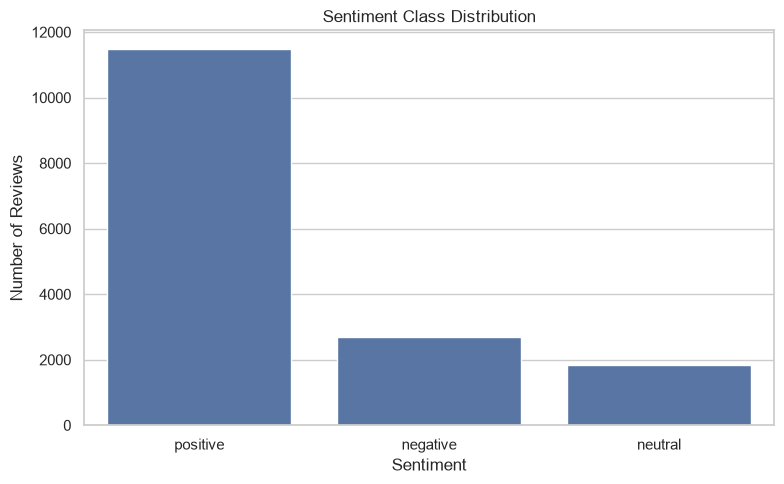

In [44]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=SENTIMENT_COLUMN,
    order=df[SENTIMENT_COLUMN].value_counts().index
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Visualize review length

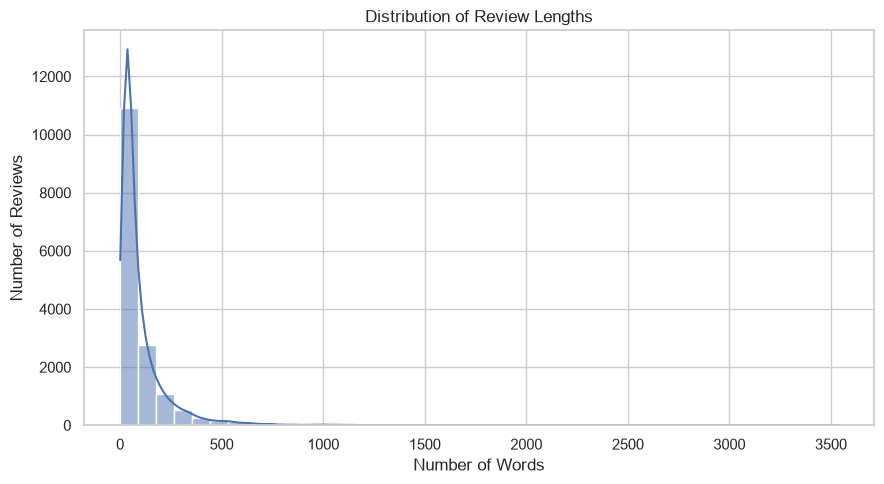

In [45]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=40,
    kde=True
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

### Compare review length by sentiment

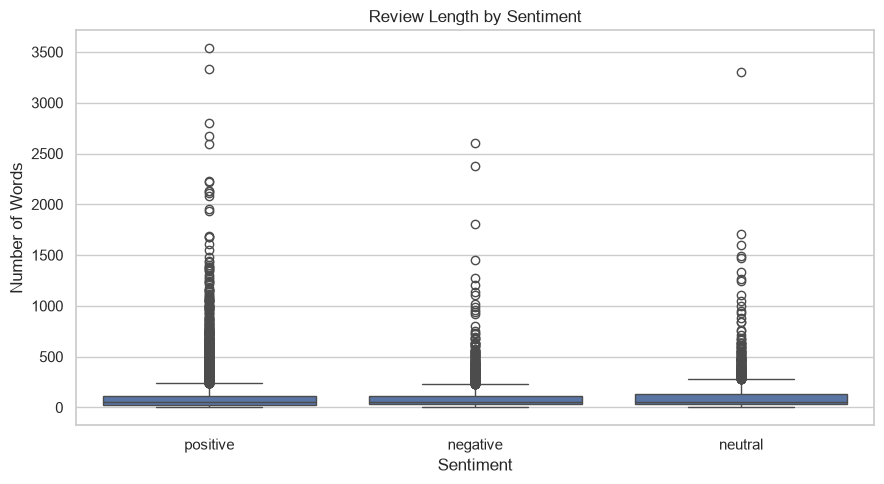

In [46]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=SENTIMENT_COLUMN,
    y="word_count"
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()